# Viterbi Segmentation

Infer a hidden low- or high-GC state from a sequence of binary observations.

The Viterbi recursion keeps the most probable complete prefix ending in each state. Transition penalties favour long runs. A backward pass follows stored best predecessors. The figure compares the decoded path with an independently known simulated path.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import logsumexp

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

State accuracy 0.992 | best-path log probability -69.54 | observation log likelihood -66.82


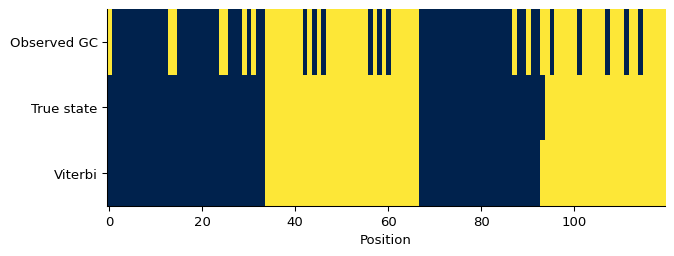

In [2]:
rng = np.random.default_rng(17)
truth = np.repeat([0, 1, 0, 1], [34, 33, 27, 26])
em = np.array([[0.80, 0.20], [0.18, 0.82]])
x = np.array([rng.choice(2, p=em[s]) for s in truth])
transition = np.log([[0.96, 0.04], [0.04, 0.96]])
v = np.log([0.5, 0.5]) + np.log(em[:, x[0]])
f = v.copy()
back = []
for obs in x[1:]:
    scores = v[:, None] + transition
    back.append(scores.argmax(0))
    v = scores.max(0) + np.log(em[:, obs])
    f = logsumexp(f[:, None] + transition, axis=0) + np.log(em[:, obs])
path = [int(v.argmax())]
for bp in reversed(back):
    path.append(int(bp[path[-1]]))
path = np.array(path[::-1])
assert v.max() <= logsumexp(f) + 1e-9
print(
    f"State accuracy {(path==truth).mean():.3f} | best-path log probability {v.max():.2f} | observation log likelihood {logsumexp(f):.2f}"
)
plt.figure(figsize=(7.2, 2.8))
plt.imshow(np.stack([x, truth, path]), aspect="auto", interpolation="nearest", cmap="cividis")
plt.yticks([0, 1, 2], ["Observed GC", "True state", "Viterbi"])
plt.xlabel("Position")
plt.tight_layout()
plt.show()

## Interpreting the result

The likelihood sums over all possible paths. Its logarithm is at least the log probability of the single best path.

## Exercise

Increase the self-transition probability and inspect short runs near a boundary.

## References

[Rabiner, hidden Markov models (1989)](https://doi.org/10.1109/5.18626)